# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets 
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_historical_data.csv')

display(df.head())
display(df.describe())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['female'].value_counts())

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64
Duplicates: 3
female
0    27903
1     1600
M        1
Name: count, dtype: int64


### Reflection: 
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. A few things look off. The lowest income is -65,600, which can't be right. The oldest age is 132 and one person has 3,345 accounts. The female column should only be 0 or 1, but one row says "M", so the column got read as text. new_car is missing 2 values and there are 3 duplicate rows. Also, product is only known after the call happens.


# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:
df_clean = df.drop_duplicates()
df_clean = df_clean[df_clean['income'] > 0]
df_clean = df_clean[df_clean['age'] < 100]
df_clean = df_clean[df_clean['num_accts'] < 10]
df_clean = df_clean[df_clean['female'] != 'M']
df_clean = df_clean.dropna()
df_clean = df_clean.drop(columns=['customer_id', 'product'])

df_clean.describe()

,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
count,29494.000000,29494.000000,29494.000000,29494.00000,29494.000000,29494.000000,29494.000000,29494.000000,29494.000000,29494.000000,29494.000000,29494.000000
mean,0.546687,33776.756628,34.770157,1.91544,1.141046,0.210382,0.681122,0.240795,1.468197,0.956398,2.345324,0.091103
std,0.497824,29375.034600,11.354699,0.65825,0.348075,0.407587,0.466050,0.427573,1.234701,1.483849,1.200677,0.287761
min,0.000000,2760.000000,19.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,26.000000,2.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,1.000000,23310.000000,32.000000,2.00000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
75%,1.000000,41690.000000,40.000000,2.00000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000
max,1.000000,159450.000000,74.000000,3.00000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,8.000000,1.000000


### Reflection: 
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed the 3 duplicate rows and then the rows with a negative income, an age over 100, more than 10 accounts, or "M" in the female column. Those values are clearly mistakes, so I deleted the rows instead of guessing what they should be. There were only 2 rows missing new_car, so I deleted those too. That was only a few rows out of about 29,500, so it doesn't really change the data.

2.6 I removed customer_id because it's just a number given to each customer and doesn't say anything about them. I also removed product, since you only know it after the customer answers the call. If I left it in, the model would basically be cheating.


## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [4]:
df_clean['answered'] = df_clean['answered'].astype(bool)
df_clean['female'] = df_clean['female'].astype(int)
df_clean['new_car'] = df_clean['new_car'].astype(int)

df_clean.dtypes

answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object

## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [5]:
df_clean['job'] = df_clean['job'].astype('category')
df_clean['chk_acct'] = df_clean['chk_acct'].astype('category')
df_clean['sav_acct'] = df_clean['sav_acct'].astype('category')

df_clean.dtypes

answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object

# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



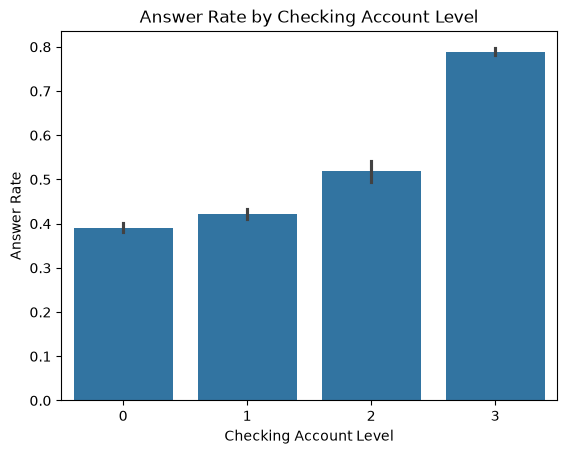

In [6]:
# Chart 3.1 🔧
sns.barplot(data=df_clean, x='chk_acct', y='answered')
plt.title('Answer Rate by Checking Account Level')
plt.xlabel('Checking Account Level')
plt.ylabel('Answer Rate')
plt.show()

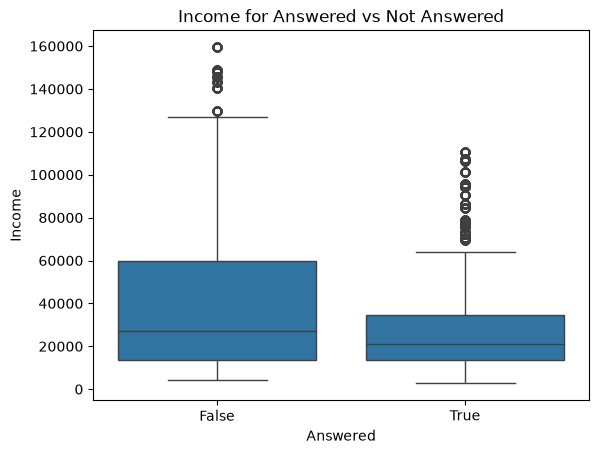

In [7]:
# Chart 3.2 🔧
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title('Income for Answered vs Not Answered')
plt.xlabel('Answered')
plt.ylabel('Income')
plt.show()

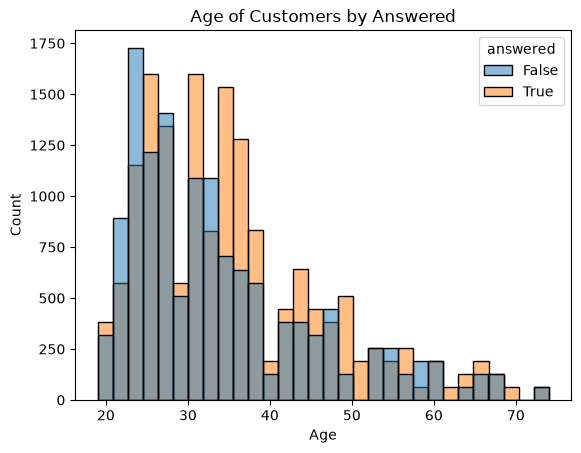

In [8]:
# Chart 3.3 🔧
sns.histplot(data=df_clean, x='age', hue='answered', bins=30)
plt.title('Age of Customers by Answered')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

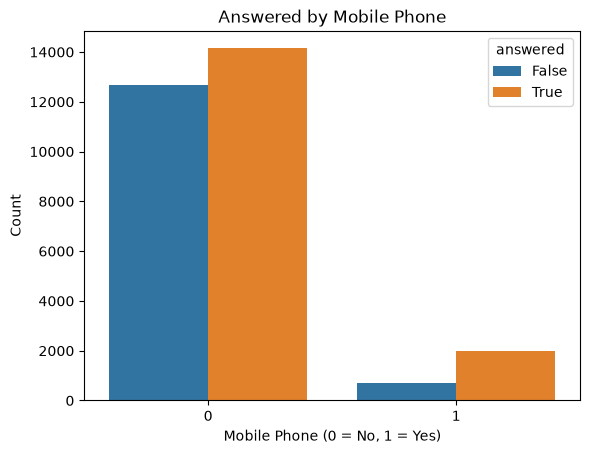

In [9]:
# Chart 3.4 🔧
sns.countplot(data=df_clean, x='mobile', hue='answered')
plt.title('Answered by Mobile Phone')
plt.xlabel('Mobile Phone (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

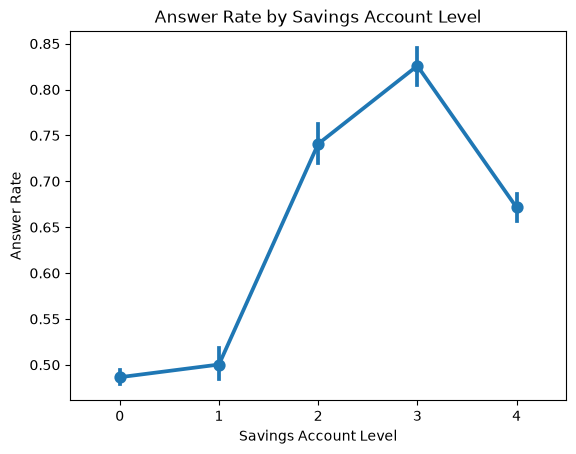

In [10]:
# Chart 3.5 🔧
sns.pointplot(data=df_clean, x='sav_acct', y='answered')
plt.title('Answer Rate by Savings Account Level')
plt.xlabel('Savings Account Level')
plt.ylabel('Answer Rate')
plt.show()

### Reflection: 
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking account level has the strongest relationship. About 79% of customers at level 3 answered, compared to about 39% at level 0. Savings account level also matters a lot, going from about 49% at level 0 to about 83% at level 3. Income matters too, since the people who didn't answer had more high incomes.

3.7. Age looked weak, since the answered and not answered groups have a pretty similar spread. Mobile shows a difference, but only a small number of people gave a mobile number. I didn't remove them. A decision tree only uses a variable when it helps, so leaving a weak one in doesn't really hurt.


## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving. 

### Do the following:
4.1 Calculate the base probability of answering  

In [11]:
base_probability = df_clean['answered'].mean()
print("Base probability of answering:", base_probability)

Base probability of answering: 0.5466874618566488


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [12]:
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

## 4.3: Create a Decision Tree

### Do the following:
- Create a tree 
- Display (visualize) the tree

Notes: 
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4 

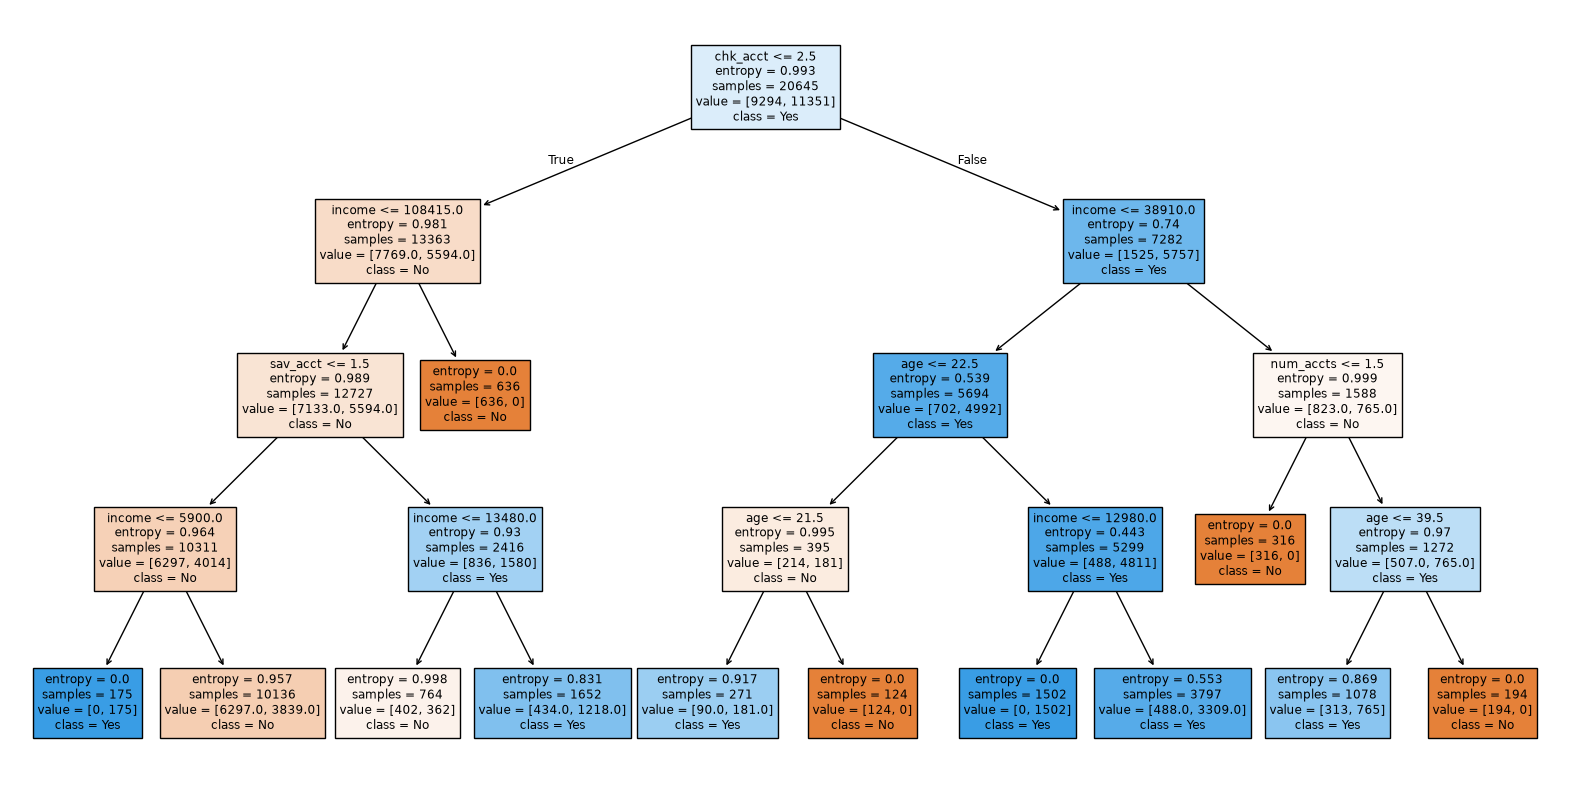

In [13]:
tree = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=1)
tree.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=X.columns, class_names=['No', 'Yes'], filled=True)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [14]:
predictions = tree.predict(X_test)
print("Tree accuracy:", accuracy_score(y_test, predictions))

Tree accuracy: 0.7276528421290541


### Reflection: 
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The base probability is about 54.7%, and the tree is right about 72.8% of the time. That's about 18 percentage points better than just guessing that everyone answers.

2. Yes. With about 50% of people not picking up, knowing ahead of time who will answer helps a lot with scheduling the sales reps. It means fewer reps sitting around waiting for calls that never happen.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [15]:
cm = confusion_matrix(y_test, predictions)
print(cm)

[[3481  595]
 [1815 2958]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

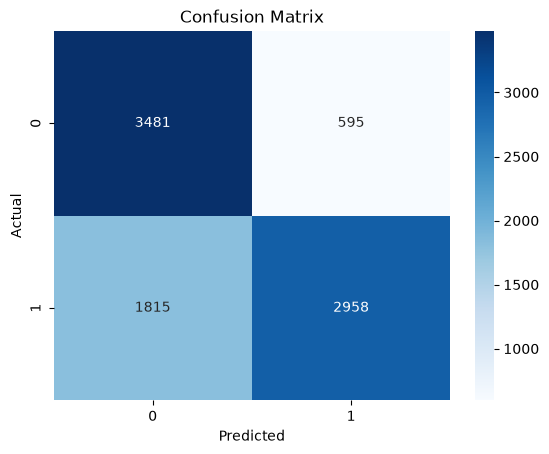

In [16]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use: 
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [17]:
tp = cm[1][1]
fp = cm[0][1]

model_profit = tp * 75 - fp * 25
print("Profit using the model:", model_profit)

Profit using the model: 206975


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called 

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [18]:
answered = y_test.sum()
not_answered = len(y_test) - answered

all_profit = answered * 75 - not_answered * 25
print("Profit calling everyone:", all_profit)

Profit calling everyone: 256075


### Reflection: 
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone made 256,075 and the model made 206,975, so the model actually made 49,100 less. The model skips a lot of people who would have answered (1,815 of them in the test set), and each of those is a lost 75.

2. Yes, it's a big amount, but in the wrong direction. Since more than half of people answer, and a sale makes 75 while a missed call only costs 25, calling everyone still comes out ahead with this first tree.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters 
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [19]:
tree2 = DecisionTreeClassifier(criterion='entropy', max_depth=8, random_state=1)
tree2.fit(X_train, y_train)

predictions2 = tree2.predict(X_test)
print("New tree accuracy:", accuracy_score(y_test, predictions2))

cm2 = confusion_matrix(y_test, predictions2)
print("New tree profit:", cm2[1][1] * 75 - cm2[0][1] * 25)

New tree accuracy: 0.8226918295852639
New tree profit: 248650


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model 
- Predict the number of customers who will be yes/no for the target variable

In [20]:
new = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_new_customer_data.csv')

new_clean = new.dropna()
new_clean = new_clean.drop(columns=['customer_id'])
new_clean['female'] = new_clean['female'].astype(int)
new_clean['new_car'] = new_clean['new_car'].astype(int)

new_predictions = tree2.predict(new_clean)
pd.Series(new_predictions).value_counts()

False    573
True     427
Name: count, dtype: int64

# Step 6: Conclusion

### Reflection: 
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Not really. The tuned tree got accuracy up to about 82% and profit up to 248,650, but that's still less than the 256,075 from calling everyone. With these numbers, every call is worth making on average, so skipping people loses money. The model did get a lot closer after tuning, though.

6.2 The model could help plan how many reps to schedule each hour, since it predicts about how many people will answer. The business could also call the predicted answerers first, or double book the time slots for people the model thinks won't answer so reps aren't sitting around.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"